# 6.2 Data cleaning and preparation

In this unit we download the credit scoring dataset and prepare it for
modeling: we re-encode the categorical columns, fix the encoded missing
values, and do the train/validation/test split.

## Downloading the dataset

First we import the libraries we need for this project:


In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

The dataset is a CSV file. We put the URL in a variable and download it
with `wget`:

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'

In [3]:
!wget $data -O ../data/CreditScoring.csv

--2026-11-01 22:30:41--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8002::154, 2606:50c0:8001::154, 2606:50c0:8003::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8002::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 182489 (178K) [text/plain]
Saving to: ‘../data/CreditScoring.csv’

../data/CreditScori 100%[===================>] 178.21K  --.-KB/s    in 0.1s    

2026-11-01 22:30:41 (1.63 MB/s) - ‘../data/CreditScoring.csv’ saved [182489/182489]



The file is small (~178K), so it downloads quickly. Let's peek inside
with `head`:

In [4]:
!head ../data/CreditScoring.csv

"Status","Seniority","Home","Time","Age","Marital","Records","Job","Expenses","Income","Assets","Debt","Amount","Price"
1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
1,0,1,36,26,1,1,1,46,107,0,0,310,910
1,1,2,60,36,2,1,1,75,214,3500,0,650,1645
1,29,2,60,44,2,1,1,75,125,10000,0,1600,1800
1,9,5,12,27,1,1,1,35,80,0,0,200,1093
1,0,2,60,32,2,1,3,90,107,15000,0,1200,1957


Each row is one customer. Now we load it with Pandas and lowercase the
column names for consistency:

In [5]:
df = pd.read_csv(data)
df.columns = df.columns.str.lower()

In [6]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


## Re-encoding the categorical variables

The columns `status`, `home`, `marital`, `records` and `job` are
categorical, but in the file they are encoded as numbers. For example,
`status` is 1, 2 or 0. That's not very intuitive, so we decode them
into strings.

Let's first look at the values of `status`:

In [7]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

So 3200 customers paid back their loans, 1254 defaulted, and there's
one record with the value 0 - an unknown status. We use dictionaries
and the Pandas `map` method to translate the numbers into strings:


In [8]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}
df.status = df.status.map(status_values)

In [9]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,1,60,30,2,1,3,73,129,0,0,800,846
1,ok,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,default,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,ok,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,ok,0,1,36,26,1,1,1,46,107,0,0,310,910


We do the same for the other categorical columns:

In [10]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

Now the dataframe is much easier to read:

In [11]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


## Missing values

Not every problem shows up as a missing value. Let's look at the
summary statistics:

In [12]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


The maximum values of `income`, `assets` and `debt` look suspicious:
99999999. This dataset encodes missing values as a long number of
nines. Instead of NaN, "unknown" became 99999999.

In [13]:
df.income.replace(to_replace=99999999, value=np.nan).max()

np.float64(959.0)

We replace these values with NaN:

In [14]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [15]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


After this, `df.describe().round()` shows the true picture - the counts
drop (income now has 4421 values instead of 4455, assets 4408, debt
4437) and the maximums become realistic.

 ## Removing the one unknown status

We also have that single customer with status `unk`. Since we only care
about the two classes - ok and default - we remove this row:

In [16]:
df.status.value_counts()

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

In [17]:
df[df.status != 'unk'].reset_index(drop=True)

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129.0,0.0,0.0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131.0,0.0,0.0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200.0,3000.0,0.0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182.0,2500.0,0.0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107.0,0.0,0.0,310,910
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4449,default,1,rent,60,39,married,no,fixed,69,92.0,0.0,0.0,900,1020
4450,ok,22,owner,60,46,married,no,fixed,60,75.0,3000.0,600.0,950,1263
4451,default,0,owner,24,37,married,no,partime,60,90.0,3500.0,0.0,500,963
4452,ok,0,rent,48,23,single,no,freelance,49,140.0,0.0,0.0,550,550


In [18]:
df = df[df.status != 'unk'].reset_index(drop=True)

This leaves 4454 rows.


## Train/validation/test split

Now we split the data. As in the previous modules, we do it in two
steps: first we split off the test set (20%), then we split the rest
into train and validation (75/25 of what remains, which gives us the
60/20/20 distribution):


In [19]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

We reset the indexes so they are fresh and unique in each dataframe:


In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

## Preparing the target variable

The models give us a probability, so the target needs to be a number.
We encode `status`: 0 for `ok`, 1 for `default`:


In [21]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

Finally, we delete `status` from the dataframes - otherwise we would
use the target as a feature, and the model would learn to cheat:

In [22]:
del df_train['status']
del df_val['status']
del df_test['status']

In [23]:
df_train.head()

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897


The data is ready. In the next unit we train our first decision tree.

## Notes
<details>

In this section we clean and prepare the [dataset](https://github.com/gastonstat/CreditScoring/raw/master/CreditScoring.csv) for the model which involves the following steps:

- Download the data from the given link.
- Reformat categorical columns (`status`, `home`, `marital`, `records`, and `job`) by mapping with appropriate values.
- Replace the maximum value of `income`, `assests`, and `debt` columns with NaNs.
- Replace the NaNs in the dataframe with `0` (*will be shown in the next lesson*).
- Extract only those rows in the column `status` who are either ok or default as value.
- Split the data in a two-step process which finally leads to the distribution of 60% train, 20% validation, and 20% test sets with random seed to `11`.
- Prepare target variable `status` by converting it from categorical to binary, where 0 represents `ok` and 1 represents `default`.
- Finally delete the target variable from the train/val/test dataframe.

# 6.3 Decision trees

In this unit we train our first decision tree with scikit-learn on the
credit scoring data, see what overfitting looks like, and learn how to
control the size of a tree.

## What a decision tree looks like

At its core, a decision tree is just a set of if/else rules. For our
credit risk problem, we could write one by hand:


In [24]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

Reading it from top to bottom: if the customer has records of previous
defaults and works part-time, we predict `default`. If they have
records but a different job, `ok`. If they have no records, we look at
their assets: more than 6000 means `ok`, otherwise `default`.

<p align="center">
  <img src="./images/03-decision-trees-01-risk-rules-tree-imagegen.jpg" alt="The same rules drawn as a tree" width="640">
</p>

Let's take one customer from the training data and check what the rules
say about them:

In [25]:
df_train.iloc[0].to_dict()

{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

In [26]:
xi = df_train.iloc[0].to_dict()
assess_risk(xi)

'ok'

Writing rules by hand doesn't scale. The point of the decision tree
algorithm is that it learns these rules from data automatically.


## Training a decision tree

We use `DecisionTreeClassifier` from scikit-learn. The features are
mixed: numeric columns and categorical ones we encoded as strings. We
turn each row into a dictionary, fill the missing values with 0, and
use `DictVectorizer` to convert the dictionaries into a feature matrix:


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [28]:
df_train.fillna(0).to_dict(orient='records')[:3]

[{'seniority': 10,
  'home': 'owner',
  'time': 36,
  'age': 36,
  'marital': 'married',
  'records': 'no',
  'job': 'freelance',
  'expenses': 75,
  'income': 0.0,
  'assets': 10000.0,
  'debt': 0.0,
  'amount': 1000,
  'price': 1400},
 {'seniority': 6,
  'home': 'parents',
  'time': 48,
  'age': 32,
  'marital': 'single',
  'records': 'yes',
  'job': 'fixed',
  'expenses': 35,
  'income': 85.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1100,
  'price': 1330},
 {'seniority': 1,
  'home': 'parents',
  'time': 48,
  'age': 40,
  'marital': 'married',
  'records': 'no',
  'job': 'fixed',
  'expenses': 75,
  'income': 121.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1320,
  'price': 1600}]

In [29]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [30]:
train_dicts[:3]

[{'seniority': 10,
  'home': 'owner',
  'time': 36,
  'age': 36,
  'marital': 'married',
  'records': 'no',
  'job': 'freelance',
  'expenses': 75,
  'income': 0.0,
  'assets': 10000.0,
  'debt': 0.0,
  'amount': 1000,
  'price': 1400},
 {'seniority': 6,
  'home': 'parents',
  'time': 48,
  'age': 32,
  'marital': 'single',
  'records': 'yes',
  'job': 'fixed',
  'expenses': 35,
  'income': 85.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1100,
  'price': 1330},
 {'seniority': 1,
  'home': 'parents',
  'time': 48,
  'age': 40,
  'marital': 'married',
  'records': 'no',
  'job': 'fixed',
  'expenses': 75,
  'income': 121.0,
  'assets': 0.0,
  'debt': 0.0,
  'amount': 1320,
  'price': 1600}]

In [31]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

In [32]:
X_train

array([[3.60e+01, 1.00e+03, 1.00e+04, ..., 0.00e+00, 1.00e+01, 3.60e+01],
       [3.20e+01, 1.10e+03, 0.00e+00, ..., 1.00e+00, 6.00e+00, 4.80e+01],
       [4.00e+01, 1.32e+03, 0.00e+00, ..., 0.00e+00, 1.00e+00, 4.80e+01],
       ...,
       [1.90e+01, 4.00e+02, 0.00e+00, ..., 0.00e+00, 1.00e+00, 2.40e+01],
       [4.30e+01, 2.50e+03, 1.80e+04, ..., 0.00e+00, 1.50e+01, 4.80e+01],
       [2.70e+01, 4.50e+02, 5.00e+03, ..., 1.00e+00, 1.20e+01, 4.80e+01]],
      shape=(2672, 29))

In [33]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

`DictVectorizer` one-hot encodes the categorical features - it creates
columns like `job=partime` and `records=no` - and leaves the numeric
ones unchanged.

Now we train the tree:

In [34]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

And check how it performs on the validation set:

In [35]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

In [36]:
y_pred = dt.predict_proba(X_val)[:, 1] # takes the frist column
roc_auc_score(y_val, y_pred)

0.6518339347557579

## Overfitting

An AUC of 0.65 is not great. What about the data the model was trained
on?

In [37]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

AUC of 1.0 on training but 0.65 on validation: the tree memorized the
training data. It learned one specific rule per customer, so on the
customers it has seen it's perfect - but these rules don't generalize
to unseen customers. This is overfitting: memorizing the data but
failing to generalize.

<p align="center">
  <img src="./images/03-decision-trees-05-memorizing-imagegen.jpg" alt="An overfit tree memorizes each customer with very specific rules" width="640">
</p>

The reason is that we let the tree grow without limits, so it became
very deep: it kept splitting until every leaf was pure.

## Controlling the size of the tree

We can restrict the depth of the tree with the `max_depth` parameter.
A shallow tree cannot memorize each customer - it has to learn broader
rules:

In [38]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [39]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

train: 0.7054989859726213
val: 0.6685264343319367


The training AUC went down, but the validation AUC went up. We traded
some accuracy on known customers for the ability to generalize.

## Looking inside the tree

To see the rules the tree learned, we use `export_text`:

In [40]:
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1



This is the tree in text form: customers without records and with more
than 6.5 years of seniority are predicted as `ok` (class 0), customers
with records who work part-time as `default` (class 1), and so on.

<p align="center">
  <img src="./images/03-decision-trees-06-learned-rules-imagegen.jpg" alt="The learned tree: first split on records, then job" width="640">
</p>

A tree with a depth of 1 - a single condition - is called a decision
stump. It's not really a tree, just one split, and it's the simplest
possible decision tree.

<p align="center">
  <img src="./images/03-decision-trees-07-decision-stump-imagegen.jpg" alt="A deep tree versus a decision stump with one split" width="640">
</p>

The question is: how does the learning algorithm decide which
condition and which threshold to use at each split? That's the topic of
the next unit.

## Notes

<details>

Decision Trees are powerful algorithms, capable of fitting complex datasets. The decision trees make predictions based on the bunch of *if/else* statements by splitting a node into two or more sub-nodes.

With versatility, the decision tree is also prone to overfitting. One of the reasons why this algorithm often overfits is its depth. It tends to memorize all the patterns in the train data but struggles to perform well on the unseen data (validation or test set).

To overcome the overfitting problem, we can reduce the complexity of the algorithm by reducing the depth size.

A decision tree with a depth of 1 is called `decision stump` and has only one split from the root.

**Classes, functions, and methods**:

- `DecisionTreeClassifier`: classification model from `sklearn.tree` class.
- `max_depth`: hyperparameter to control the maximum depth of decision tree algorithm.
- `export_text`: method from `sklearn.tree` class to display the text report showing the rules of a decision tree.

*Note*: we have already covered `DictVectorizer` in session 3 and `roc_auc_score` in session 4 respectively.

# 6.4 Decision tree learning algorithm

In this unit we look inside the decision tree learning algorithm: how
it finds the best condition for a split, what impurity is, and when it
stops splitting.

## Tree vocabulary

First, the names for the parts of a tree:

- A node contains a condition, for example `assets > 3000`.
- Two branches go out of it: one for "true" and one for "false".
- The node at the top is the root; every node except the leaves is a
  parent of two other nodes.
- The nodes at the bottom are leaves (decision nodes): this is where
  the tree stops and the prediction is made.
- The depth of a tree is the number of levels - the length of the
  longest path from the root to a leaf.

To understand how the algorithm learns such a tree, we take a small
toy dataset instead of the full credit scoring data.

## Finding the best split for one column

We take eight customers with one feature, `assets`, and the target,
`status`:

In [41]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])
df_example

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


We want to build a decision stump - a tree with one condition,
`assets > T`. The question is: which threshold `T` is the best?

The condition splits the data into two parts: the left side where the
condition is false (`assets <= T`) and the right side where it is true
(`assets > T`). The candidate thresholds are the values in the middle
between the observed values - if we sort by `assets`, the candidates
are:

In [42]:
Ts = [0, 2000, 3000, 4000, 5000, 8000]

Thresholds 0 and 8000 don't really make sense (one side would be
empty), but the algorithm still tries them. Let's split with
`T = 4000`:

In [43]:
T = 4000
df_left = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display("df_LEFT", df_left)
print(df_left.status.value_counts(normalize=True))
display("df_RIGHT", df_right)
print(df_right.status.value_counts(normalize=True))

'df_LEFT'

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


'df_RIGHT'

,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


The left side has four customers: three `default` and one `ok`. The
right side: three `ok` and one `default`.

For each side we predict the majority class - the most frequent status.
Left: `default`. Right: `ok`. The mistake rate on the left is 1/4 =
25% (the one `ok` customer), and on the right also 1/4 = 25%.

This mistake rate is called the misclassification rate, and it is one
way of measuring how impure a group is. A pure group contains only one
class - zero misclassification rate. We can compute the rates for both
sides with `value_counts(normalize=True)` and average them, weighted by
the group sizes:


In [44]:
from IPython.display import display, HTML

def display_side_by_side(*frames, titles=()):
    html = '<div style="display:flex; gap:40px; align-items:flex-start;">'
    for i, df in enumerate(frames):
        title = titles[i] if i < len(titles) else ''
        html += f'<div><h4>{title}</h4>{df.to_html()}</div>'
    html += '</div>'
    display(HTML(html))

for T in Ts:
    print(T)
    df_left = df_example[df_example.assets <= T]
    df_right = df_example[df_example.assets > T]

    display_side_by_side(
        df_left,
        df_left.status.value_counts(normalize=True).to_frame(),
        df_right,
        df_right.status.value_counts(normalize=True).to_frame(),
        titles=('df_LEFT', 'LEFT status', 'df_RIGHT', 'RIGHT status'),
    )
    print()

0



2000



3000



4000



5000



8000


```text
T    decision LEFT   impurity LEFT   decision RIGHT  impurity RIGHT  AVG
0    default         0%              ok              43%             21%
2000 default         0%              ok              33%             16%
3000 default         0%              ok              20%             10%
4000 default         25%             ok              25%             25%
5000 default         50%             ok              50%             50%
8000 default         43%             ok              0%              21%
```

The best threshold is `T = 3000`: the average impurity is <u>**only 10% (beeing the lowest one)**</u>. So
the best split for this column is `assets > 3000`.

```text
       ASSETS > 3000 
        /         \                            
   FALSE           TRUE
   DEFAULT         OK
```

## Checking multiple features

Real data has many features, and the algorithm needs to find the best
split among all of them. Let's add a second feature, `debt`:


In [45]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])

In [46]:
df_example

,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


For `debt` the candidate thresholds are `[500, 1000, 2000]`. We put all
thresholds in a dictionary and loop over both features and all their
thresholds:

In [47]:
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000]
}

for feature, Ts in thresholds.items():
    print('#####################')
    print(feature)
    for T in Ts:
        print(T)
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        display("df_LEFT", df_left)
        print(df_left.status.value_counts(normalize=True))
        display("df_RIGHT", df_right)
        print(df_right.status.value_counts(normalize=True))

        print()
    print('#####################')

#####################
assets
0


'df_LEFT'

,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


'df_RIGHT'

,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


... (45 outputs left out)

status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


'df_RIGHT'

,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#####################


In [48]:
import pandas as pd

rows = []
for feature, Ts in thresholds.items():
    for T in Ts:
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        left = df_left.status.value_counts(normalize=True).add_prefix('left_')
        right = df_right.status.value_counts(normalize=True).add_prefix('right_')

        row = pd.concat([left, right])
        row['feature'] = feature
        row['T'] = T
        rows.append(row)

summary = pd.DataFrame(rows).set_index(['feature', 'T']).fillna(0)
display(summary)

status        left_default  right_ok  right_default   left_ok
feature T                                                    
assets  0         1.000000  0.571429       0.428571  0.000000
        2000      1.000000  0.666667       0.333333  0.000000
        3000      1.000000  0.800000       0.200000  0.000000
        4000      0.750000  0.750000       0.250000  0.250000
        5000      0.500000  0.500000       0.500000  0.500000
        8000      0.571429  1.000000       0.000000  0.428571
debt    500       0.000000  0.428571       0.571429  1.000000
        1000      0.333333  0.000000       1.000000  0.666667
        2000      0.428571  0.000000       1.000000  0.571429

For `debt`, the best split gives an average impurity of 16% - worse
than the 10% we got with `assets`. So the best split overall is still
`assets > 3000`. With more features we would simply add more rows to
this comparison.

In [49]:
summary['imp_left']  = 1 - summary[['left_default', 'left_ok']].max(axis=1)
summary['imp_right'] = 1 - summary[['right_default', 'right_ok']].max(axis=1)
summary['avg'] = (summary.imp_left + summary.imp_right) / 2
summary.sort_values('avg')

status        left_default  right_ok  right_default   left_ok  imp_left  \
feature T                                                                 
assets  3000      1.000000  0.800000       0.200000  0.000000  0.000000   
        2000      1.000000  0.666667       0.333333  0.000000  0.000000   
debt    1000      0.333333  0.000000       1.000000  0.666667  0.333333   
assets  0         1.000000  0.571429       0.428571  0.000000  0.000000   
        8000      0.571429  1.000000       0.000000  0.428571  0.428571   
debt    500       0.000000  0.428571       0.571429  1.000000  0.000000   
        2000      0.428571  0.000000       1.000000  0.571429  0.428571   
assets  4000      0.750000  0.750000       0.250000  0.250000  0.250000   
        5000      0.500000  0.500000       0.500000  0.500000  0.500000   

status        imp_right       avg  
feature T                          
assets  3000   0.200000  0.100000  
        2000   0.333333  0.166667  
debt    1000   0.000000  0.166667  
assets  0      0.428571  0.214286  
        8000   0.000000  0.214286  
debt    500    0.428571  0.214286  
        2000   0.000000  0.214286  
assets  4000   0.250000  0.250000  
        5000   0.500000  0.500000

## The split-finding algorithm

In pseudocode, finding the best split works like this:

```text
FOR each feature in FEATURES:
    FIND all thresholds for the feature
    FOR each threshold in thresholds:
        SPLIT the dataset using "feature > threshold" condition
        COMPUTE the impurity of this split
SELECT the condition with the LOWEST IMPURITY
```

The misclassification rate is not the only impurity measure.
Scikit-learn uses more sensitive criteria: Gini impurity and entropy.
For regression trees the equivalent is MSE. The idea stays the same:
pick the split with the lowest impurity. And while we looked at
classification here, decision trees can also solve regression problems.

## Stopping criteria

After the root is split, the algorithm applies the same procedure
recursively to the left and right sides. When does it stop?

- The group is already pure - the misclassification rate is 0%, no
  point in splitting further.
- The tree reached the maximum depth limit - controlled by
  `max_depth`.
- The group is too small to split - controlled by `min_samples_leaf`.
- The maximum number of leaves (decision nodes) was reached.

These stopping criteria are what keep a tree from overfitting.

## The full algorithm

Putting everything together:

- Find the best split: for every feature, try all possible thresholds
  and pick the condition with the lowest impurity.
- If the stopping criteria are not met (max depth not reached, groups
  large enough and not pure), repeat for the left side and the right
  side.

In the next unit we tune `max_depth` and `min_samples_leaf` for our
credit scoring project.

## Notes

<details>


This lesson first reviews the topics learned in the previous lesson about how to train a decision tree using scikit-learn, and handle a decision tree model not generalizing well due to overfitting of the data. 

In this lesson, we learn about how to best split a decision tree and different classification criteria that can be used to split a tree. We dive deep in an example, splitting trees with `misclassification` criteria. Additionally, different stopping criteria to break the iterative tree split are discussed.     

* **Structure of a decision tree**: A decision tree is a data structure 
composed of **nodes** (which contain conditions) and **branches** (which represent the values for a condition: True or False).  The tree starts with a **root node**, which is the parent of two other nodes, and each of these nodes can also be the parent of others. At the last level of the tree, there are terminal nodes, also called **leaves**.

* **Depth of a decision tree**: The **depth** of a tree is the number of levels it has, or simply the length of the longest path from the root node to a leaf node.
  
* **Rules & Conditions, Thresholds**: The learning algorithm for a decision tree involves determining the best **conditions** to split the data at each node in order to achieve the best possible classifier. When there are many **features**, the algorithm considers each feature with its optimized **threshold** to determine the best feature for splitting at a particular node. In essence, at each node, the algorithm evaluates all possible thresholds for every feature and calculates the resulting misclassification rate. It then selects the condition
(feature and threshold) that yields the lowest impurity.

* **Misclassification rate**: After each split, the goal is to divide the data into two sets that are as **pure** as possible. This means that the data within each set should belong predominantly to either one class, or the other. Another way to describe this is to aim for the lowest possible **misclassification rate** (impurity). The misclassification rate is a weighted average of the error rates obtained after splitting the data into two sets.  The predicted class for each set is determined by the **majority class** present in this set.

* **Impurity criteria**: Common misclassification rate measurements are **GINI Impurity** and **Entropy**. It is also possible to use **MSE** for regression problems.
  
* **Decision trees can be used to solve regression problems**: While we focused on decision tree classifiers, it's important to note that decision trees can also be applied to regression problems using decision tree regressors.

* **Stopping Criteria**: The process of recursively splitting the data at each child node eventually stops based on certain **stopping criteria**. These criteria prevent the model from overfitting and include:

    *   The group is already **pure**: 0% impurity.
    *   The **maximum depth** has been reached.
    *   The group is **smaller** than the minimum size set for groups.
    *   The maximum number of **leaves/terminal nodes** has been reached.
</details>

#### Decision Tree Learning Algorithm in a Nutshell

*   At a node, find the best split.
*   Stop if max\_depth is reached.
*   For each child node, if the node is sufficiently large and not pure, repeat the process from the beginning.

# 6.5 Decision trees parameter tuning

In this unit we tune the decision tree: we try different values of
`max_depth` and `min_samples_leaf`, pick the combination with the best
validation AUC, and look at the final tree.

## Which parameters to tune

`DecisionTreeClassifier` has many parameters - `criterion`, which is
the impurity measure, `max_depth`, `min_samples_leaf`, and others. The
two that matter most are:

- `max_depth` - the maximum number of levels. It limits how specific
  the rules can get.
- `min_samples_leaf` - the minimum number of samples in a leaf. It
  prevents the tree from creating leaves that cover just one or two
  customers.

Tuning means selecting the values that give the best score on the
validation set - AUC in our case.

## Selecting max_depth

We start with `max_depth` alone. We try depths from 1 to 20, plus
`None` (no limit), and record the validation AUC for each:

In [50]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.766
   6 -> 0.757
  10 -> 0.701
  15 -> 0.673
  20 -> 0.662
None -> 0.658


Depths 4, 5 and 6 are the best (AUC around 0.76). Trees that are too
shallow underfit; deep trees overfit and end up worse than the simple
ones.

## Adding min_samples_leaf

Now we take the promising depths - 4, 5 and 6 - and for each of them
try several values of `min_samples_leaf`. We store the results as
tuples in a list:

In [51]:
scores = []

for depth in [4, 5, 6]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

Then we put the scores into a dataframe:


In [52]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

The sorted dataframe is hard to scan. It's easier to reshape it: rows
for `min_samples_leaf`, columns for `max_depth`, and the AUC in the
cells. That's what the `pivot` method does:


In [53]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc              
max_depth             4      5      6
min_samples_leaf                     
1                 0.761  0.767  0.757
5                 0.761  0.768  0.762
10                0.761  0.762  0.778
15                0.764  0.773  0.786
20                0.761  0.774  0.774
100               0.756  0.763  0.776
200               0.747  0.759  0.768
500               0.680  0.680  0.680

Even easier to read as a heatmap - the best cell is the lightest one:

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

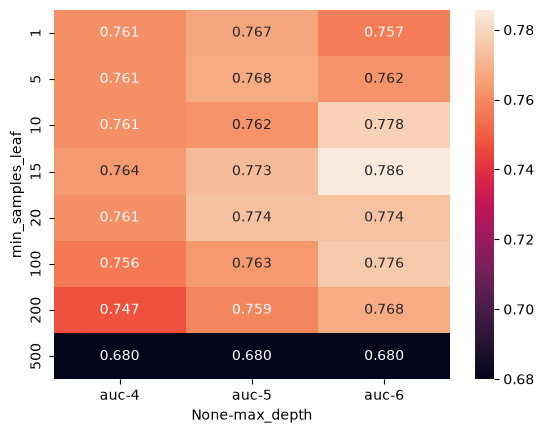

In [54]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

The best combination is `max_depth=6` and `min_samples_leaf=15`, with
an AUC of 0.785 - better than anything we saw when tuning `max_depth`
alone.

Note that we only searched depths 4-6 for the second parameter. On a
large dataset it would be too slow to try every combination, so we
first select `max_depth` and then tune the rest. On this small dataset
we could afford to check more combinations - and if we did, other
close pairs would show up. It's a good habit to start with a coarse
search and refine it.


In [55]:
scores = []

for depth in [4, 5, 6, 7, 10, 15, 20, None]: # with more values
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                                                 
max_depth           NaN   4.0    5.0    6.0    7.0    10.0   15.0   20.0
min_samples_leaf                                                        
1                 0.651  0.761  0.766  0.754  0.755  0.692  0.660  0.648
5                 0.713  0.761  0.768  0.760  0.756  0.729  0.717  0.720
10                0.766  0.761  0.762  0.778  0.765  0.769  0.759  0.760
15                0.786  0.764  0.772  0.785  0.780  0.788  0.787  0.789
20                0.785  0.761  0.774  0.774  0.779  0.783  0.784  0.783
100               0.779  0.756  0.763  0.776  0.780  0.780  0.779  0.780
200               0.768  0.747  0.759  0.768  0.768  0.768  0.768  0.768
500               0.680  0.680  0.680  0.680  0.680  0.680  0.680  0.680

In [56]:
df_scores.sort_values(by="auc", ascending=False).head()

,max_depth,min_samples_leaf,auc
51,20.0,15,0.788522
35,10.0,15,0.787532
43,15.0,15,0.787496
59,NaN,15,0.786352
19,6.0,15,0.785080


<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

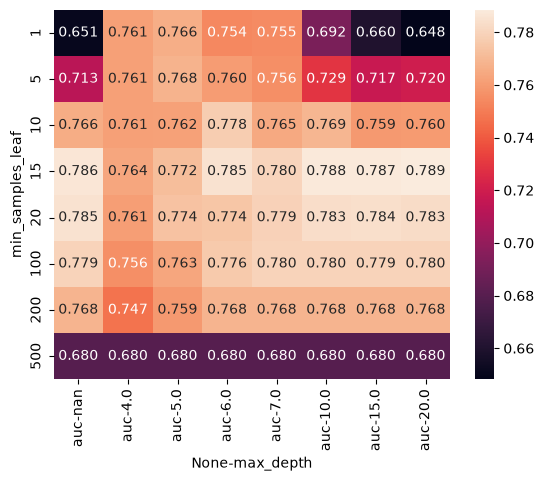

In [57]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

## The final tree
Let's train the tree with the tuned parameters and look at the rules it
learned:

In [58]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- assets <= 4250.00
|   |   |   |   |--- income <= 20.00
|   |   |   |   |   |--- seniority <= 1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- seniority >  1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  20.00
|   |   |   |   |   |--- expenses <= 71.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- expenses >  71.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  4250.00
|   |   |   |   |--- debt <= 1600.00
|   |   |   |   |   |--- seniority <= 2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- seniority >  2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- debt >  1600.00
|   |   |   |   |   |--- class: 1
|   |   |--- income >  74.50
|   |   |   |--- seniority <= 5.50
|   |   |   |   |--- amount <= 1330.00
|   |   |   |   |   |--- assets <= 3326.00
|   |   |   |   |   |   |--- clas

This tree is still readable, unlike the unlimited one from before: it
starts with `records`, then looks at `seniority`, `amount`, `price` and
`assets` to decide whether a customer is likely to default.

One caution: when you scan the results, watch out for parameter values
that don't make sense, like `nan` creeping into the grid. A
combination can show a good score by accident - check that the values
you pick actually control the size of the tree the way you intend.

## Notes

In this lesson, we will discuss about different parameters used to control a Decision Tree (DT). Two of them, `max_depth` and `min_samples_leaf` have a greater importance than the others. We will further see how we first tune `max_depth` parameter and then move to tuning other parameters will help. After that, a dataframe will be created with all possible combinations of `max_depth`, `min_sample_leaf` and the auc score corresponding to them. These results will be visualized using a heatmap by pivoting the dataframe to easily determine the best possible `max_depth` and `min_samples_leaf` combination. Finally, the DT will be retrained using the identified parameter combination. The DT so trained will be viewed as a tree diagram, for visualizing decision rules.     

### Steps
* **Fine-Tuning Process:** iterate to find optimal parameter settings.
    *   Start by tuning `max_depth` with various values to determine a subset of optimal
depths.
    *   Then, using this subset, fine-tune the model further by exploring different
`min_samples_leaf` values.

    This method is computationally efficient for **large datasets**, though it may not be optimal for smaller ones.

* **Heatmaps for Visualization:** Store the scores (e.g., AUC) obtained during tuning in a pivot table, and create a heatmap with `seaborn` to easily identify high score areas, which helps pinpoint the optimal `max_depth` and `min_samples_leaf` combination.

**NB:** Choose parameter values that effectively control the tree's size and avoid values like 'nan' (Not a Number), even if they seem to lead to better scores.

### Importance of  `max_depth` and `min_samples_leaf`

*   **Controlling Overfitting:** these parameters play a critical role in preventing overfitting.
    *   `max_depth` limits the tree's complexity, preventing it from growing too deep and memorizing the training data.
    *   `min_samples_leaf` ensures that leaf nodes have a sufficient number of samples,
reducing the chance of creating nodes that are too specific to the training data.

*   **Impact on Bias and Variance:** They also affect the model's bias and variance.
    *   Increasing `max_depth` and decreasing `min_samples_leaf` can lead to a more complex model with lower bias but higher variance.
    *   Decreasing `max_depth` and increasing `min_samples_leaf` results in a simpler model with higher bias but lower variance.
      
It's then important to find the right balance between `max_depth` and `min_samples_leaf` to achieve optimal model performance.
This involves a trade-off between bias and variance, and the best values depend on the specific dataset and problem.

# 6.6 Ensemble learning and random forest

In this unit we combine many decision trees into one model. We start with the
idea behind it - asking a board of experts instead of trusting a single one -
then build a random forest with scikit-learn and tune its three main
parameters.


## Board of experts

So far we score a loan application with a single decision tree: the features
of the client go in, the tree outputs the probability of default, and the
bank uses this score to approve or reject the application.

Instead of one expert, imagine a board of five experts. When a client
submits an application, it goes to each of them. Every expert looks at the
application and decides: approve or reject. The final decision is made by
majority vote. The idea is that the collective opinion of five experts is
more reliable than the opinion of one.

<p align="center">
  <img src="./images/06-random-forest-01-board-of-experts-imagegen.jpg" alt="Random forest: each expert sees a random subset of features, gives a probability of default, and the final prediction is the average of all probabilities" width="640">
</p>

We can do the same with models. Instead of five people, we have five models
- g1, g2 and so on - and each of them returns its probability of default.
To combine them, we take the average of these probabilities:

```text
(1/n) * (p1 + p2 + ... + pn)
```

Combining several models this way is called ensembling, and the individual
models are often called "weak learners": each one alone is not great, but
together they are stronger than any single model.


## Random forest

When the models we ensemble are decision trees, the ensemble is called a
random forest. But it cannot be just any group of trees - the trees need to
be different from each other. If we simply train the same tree several times
on the same data with the same parameters, we get identical trees that
produce identical predictions, and averaging them gives exactly the same
result as a single tree.

The "random" in random forest is what makes the trees diverse: each tree
gets a random subset of features, and - depending on the `bootstrap`
parameter - a randomly resampled copy of the training data. To see the idea,
suppose we have three features: `assets`, `debt` and `price`, and we train
three trees. The first tree may see `assets` and `debt`, the second `assets`
and `price`, and the third `debt` and `price`. Each tree gives its own
prediction - p1, p2 and p3 - and the final prediction is the average:
1/3 (p1 + p2 + p3).

<p align="center">
  <img src="./images/06-random-forest-02-random-forest-imagegen.jpg" alt="A board of three decision trees: each is trained on a different pair of features, and their predictions are averaged" width="640">
</p>

In scikit-learn, random forest lives in the `ensemble` package. Let's take our
credit scoring data and train a random forest with a varying number of trees -
from 10 to 200 with a step of 10 - and see how the number of trees affects the
AUC on validation:

In [59]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

In [60]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])

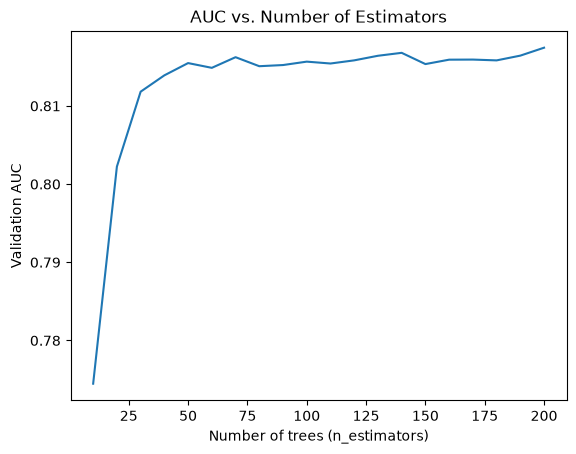

In [61]:
plt.plot(df_scores.n_estimators, df_scores.auc, )
plt.title('AUC vs. Number of Estimators')
plt.xlabel('Number of trees (n_estimators)')
plt.ylabel('Validation AUC')
plt.show()

The curve grows quickly at the beginning and then stabilizes: after some
number of trees, adding more of them does not improve the score. Still, more
trees never hurt the quality - the curve stays flat - so the main cost of
extra trees is training time, not accuracy. This is why `n_estimators` is
usually set to "as many as you can afford", and we tune the other parameters
first. Approx : `50 [n_estimators]`

## Tuning max_depth

Now let's tune `max_depth`, the maximum depth of each tree in the forest. We
use the same loop, but this time we try three values of `max_depth` - 5, 10
and 15 - and for each of them we again iterate over the number of trees:


In [62]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

To compare the three depths, we plot each of them as a separate line:

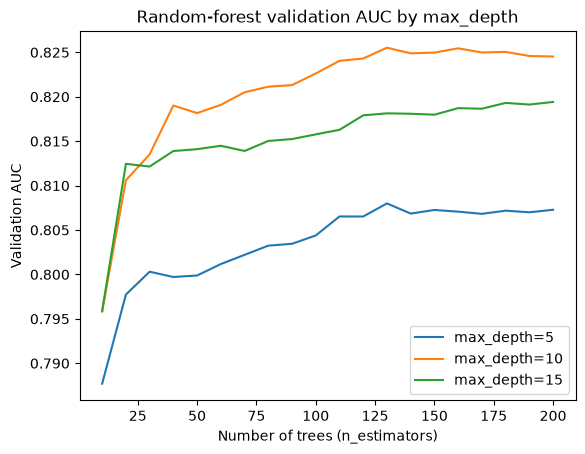

In [63]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.title("Random-forest validation AUC by max_depth")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Validation AUC")
plt.legend()

The curves for `max_depth=10` and `max_depth=15` are clearly better than the
one for `max_depth=5`, and `max_depth=10` is the best of the three. So we fix
it:

In [64]:
max_depth = 10

## Tuning min_samples_leaf

The third parameter is `min_samples_leaf` - the minimal number of observations
allowed in a leaf of a tree. We repeat the same procedure: keep `max_depth`
fixed at 10 and try `min_samples_leaf` of 1, 3, 5, 10 and 50, each combined
with a varying number of trees:

In [65]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

And plot all five curves, giving each value its own color:


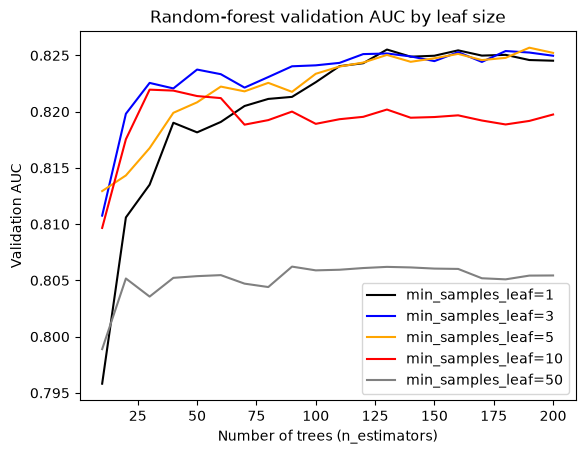

In [66]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)


plt.title("Random-forest validation AUC by leaf size")
plt.ylabel("Validation AUC")
plt.xlabel("Number of trees (n_estimators)")
plt.legend()

The curves with small values - 1, 3 and 5 - are close to each other at the
top, while 10 and especially 50 are worse. We take `min_samples_leaf=3`:

In [67]:
min_samples_leaf = 3

## The final model

With the parameters selected, we train the final random forest with 200 trees:

In [68]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

There are other useful parameters for random forest - for example
`max_features`, which controls the size of the random feature subset each tree
sees, and `bootstrap`, which controls whether each tree is trained on a
randomly resampled copy of the data. We don't tune them here, but they are
worth knowing - see the
[RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
for the full list.


## Notes

<details><br>

**Ensemble learning** is a machine learning paradigm where multiple models, often referred to as 'weak learners', are strategically combined to solve a particular computational intelligence problem. This approach frequently yields superior predictive performance compared to using a single model.

**Random Forest** is an example of ensemble learning where each model is a decision tree and their predictions are aggregated to identify the most popular result. Random forest only selects a random subset of features from the original data to make predictions. The 'randomness' in Random Forest stems from two key aspects: 

- Each tree is potentially trained on a bootstrapped sample of the original data, introducing randomness at the row level.
- At each node during tree construction, only a random subset of features is considered for splitting. This feature randomness helps decorrelate the trees, preventing overfitting and promoting generalization to unseen data.

**Bootstrapping** is a resampling technique where numerous subsets
of the data are created by sampling the original data with replacement. This means that
some data points may appear multiple times in a single bootstrap sample, while others may
be excluded. In Random Forest, each decision tree is trained on a distinct bootstrap sample,
further contributing to the diversity and robustness of the ensemble.

**Parameter tuning** is crucial for optimizing the performance of a
Random Forest model.  Two critical parameters are `max_depth`, which controls the maximum
depth of each decision tree, and `n_estimators`, which determines the number of trees in
the forest. Increasing `max_depth` allows for more complex trees, potentially leading to
overfitting. Conversely, a larger `n_estimators` generally improves model accuracy but
increases computational cost.

In random forests, the decision trees are trained independently to each other.

**Classes, functions, and methods**:

- `from sklearn.ensemble import RandomForestClassifier`: random forest classifier from sklearn ensemble class.
- `plt.plot(x, y)`: draw line plot for the values of y against x values.

---

# 6.7 Gradient boosting and XGBoost

In this unit we look at the second way of combining many models: gradient
boosting. Unlike random forest, where trees are trained independently,
boosting trains models one by one, each next model fixing the errors of the
previous ones. We use XGBoost - the most popular implementation of gradient
boosting - to train our first model and to monitor how it learns.


## Boosting vs random forest

In random forest, all the trees are trained in parallel: each tree gets a
random subset of features, they don't talk to each other, and their
predictions are averaged at the end.

Gradient boosting works sequentially. First we train one model and look at
where it makes errors. Then we train the second model on these errors, so it
learns to fix the mistakes of the first one. The third model fixes the errors
of the second one, and so on. The final prediction combines what all the
models in the sequence have learned.

<p align="center">
  <img src="./images/07-boosting-01-boosting-vs-random-forest-imagegen.jpg" alt="Random forest trains models in parallel; boosting trains them sequentially, each model learning the errors of the previous one" width="640">
</p>

When the models in this sequence are decision trees, the method is called
gradient boosting trees:

<p align="center">
  <img src="./images/07-boosting-02-gradient-boosting-trees-imagegen.jpg" alt="Gradient boosting trees: each tree is trained on the errors of the previous model, and the final prediction combines all of them" width="640">
</p>

## Installing XGBoost

XGBoost is not part of scikit-learn, so first we install it:

In [69]:
!uv add xgboost

Resolved 124 packages in 21ms
Checked 49 packages in 10ms


<div class="alert alert-block alert-info">
<b>NOTE:</b><br>
For macos require the `libomp` library.<br> <code>brew install libomp</code>
</div>

For macos require the 'libomp' library.


And import it - by convention it is imported as `xgb`:

In [70]:
import xgboost as xgb

## Wrapping the data into DMatrix

XGBoost does not work with NumPy arrays directly. Instead, we wrap the data
into a special data structure called `DMatrix`, which is optimized for
training XGBoost models. We create it from the feature matrix and the target
array, and also pass the feature names:

In [71]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

## Training the first model

We train the model with `xgb.train`, which takes a dictionary of parameters,
the training DMatrix, and the number of boosting rounds - the number of
models in our sequence. We start with ten rounds:

In [76]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

A few of these parameters are worth explaining:

- `eta` is the learning rate - how large the correction each next model
  applies is.
- `max_depth` and `min_child_weight` control the size of the trees, same as
  `max_depth` and `min_samples_leaf` in decision trees and random forest.
- `objective` is the task we are solving - `binary:logistic` is binary
  classification, and it makes the model output probabilities.

After training, we predict with `model.predict(dval)` and evaluate:

In [77]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8156256811411687

This gives us 0.8152745150274878 - already better than the tuned decision
tree, with just ten rounds.


## Performance monitoring

Ten rounds was a blind shot: we don't know how the model behaves during
training. To watch it learn, we pass a watchlist - a list of datasets to
evaluate after each round. By default XGBoost monitors logloss, the metric
it optimizes, but that is hard to interpret - so we switch the evaluation
metric to AUC, the metric we have been using all along. We also train for
200 rounds now, and ask XGBoost to print the metrics every five rounds:

In [78]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [81]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [95]:
print('\n'.join(output.stdout.splitlines()[:15]), "\n and so on ...")

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710 
 and so on ...


In [98]:
std_opt = output.stdout

In [100]:
line = std_opt.split('\n')[0]
line

'[0]\ttrain-auc:0.86632\tval-auc:0.77998'

In [101]:
num_iter, train_auc, val_auc = line.split('\t')

In [103]:
print(num_iter, train_auc, val_auc)

[0] train-auc:0.86632 val-auc:0.77998


In [108]:
for line in output.stdout.strip().split('\n'):
    if not line.startswith('['):
        continue
    it = int(line[1:line.index(']')])
    if it <= 500 and it % 10 == 0:
        print(line)

[0]	train-auc:0.86632	val-auc:0.77998
[10]	train-auc:0.95391	val-auc:0.82002
[20]	train-auc:0.97677	val-auc:0.82239
[30]	train-auc:0.98805	val-auc:0.82061
[40]	train-auc:0.99474	val-auc:0.81732
[50]	train-auc:0.99753	val-auc:0.81320
[60]	train-auc:0.99893	val-auc:0.80818
[70]	train-auc:0.99955	val-auc:0.80710
[80]	train-auc:0.99987	val-auc:0.80813
[90]	train-auc:0.99995	val-auc:0.80782
[100]	train-auc:0.99999	val-auc:0.80839
[110]	train-auc:1.00000	val-auc:0.80730
[120]	train-auc:1.00000	val-auc:0.80570
[130]	train-auc:1.00000	val-auc:0.80457
[140]	train-auc:1.00000	val-auc:0.80320
[150]	train-auc:1.00000	val-auc:0.80253
[160]	train-auc:1.00000	val-auc:0.80376
[170]	train-auc:1.00000	val-auc:0.80277
[180]	train-auc:1.00000	val-auc:0.80321
[190]	train-auc:1.00000	val-auc:0.80347


The train AUC grows quickly towards its maximum, while the validation AUC
flattens out. That is the signature of overfitting: after some number of
rounds, the model keeps improving on the training data without getting better
on unseen data.

## Parsing the monitoring output

To analyze these numbers with pandas, we parse the captured text into a
dataframe - each line gives us the iteration number and the two AUC values:


In [109]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

Now we can plot both AUC curves against the iteration number:

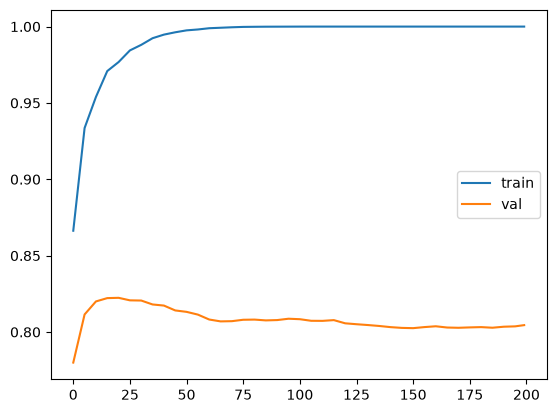

In [110]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

# 6.8 XGBoost parameter tuning

In the previous unit we trained an XGBoost model with default parameters and
learned how to monitor its progress. Now we tune the three most important
XGBoost parameters - `eta`, `max_depth` and `min_child_weight` - using the
train/validation curves we learned to parse.

## The parameters to tune

The three parameters we tune are:

1. `eta` - the learning rate. It controls the size of the step each next
   model takes when correcting the errors of the previous ones.
2. `max_depth` - the maximum depth of each tree.
3. `min_child_weight` - the minimal size of a leaf, the analogue of
   `min_samples_leaf` in random forest.

<p align="center">
  <img src="./images/08-xgb-tuning-01-parameters-imagegen.jpg" alt="The three XGBoost parameters to tune: eta is the size of the step, max_depth controls the trees, and min_child_weight is a rough analogue of min_samples_leaf in random forest" width="640">
</p>

XGBoost has many more parameters - we tune only these three, in this order:
first `eta`, then `max_depth`, then `min_child_weight`. For each parameter we
train a model per value, parse the monitoring output with the
`parse_xgb_output` function from the previous unit, and compare the
validation AUC curves.

## Tuning eta

We keep a dictionary `scores` that maps the parameter value to the parsed
learning curve. For each value of `eta`, we train a model, capture the output
and store the parsed dataframe:


In [140]:
scores = {}

In [134]:
%%capture output 

# repeat this code with [0.3, 1.0, 0.1, 0.05, 0.01]

xgb_params = {
    'eta': 0.05,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [135]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.05'

In [136]:
scores.keys()

dict_keys(['eta=0.01', 'eta=1.0', 'eta=0.3', 'eta=0.1', 'eta=0.05'])

In [115]:
scores['eta=0.01']

,num_iter,train_auc,val_auc
0,0,0.86632,0.77998
1,5,0.87007,0.77821
2,10,0.87208,0.77838
3,15,0.87381,0.78277
4,20,0.87584,0.78719
5,25,0.88595,0.79571
6,30,0.89329,0.80000
7,35,0.89642,0.79971
8,40,0.89881,0.79866
9,45,0.90066,0.79690


This gives us `'eta=0.01'`. We repeat this - changing the value of `eta` in
the parameters - for 0.3, which is the value we used before, and then 1.0,
0.1 and 0.05. Then we plot the validation AUC of every run on one chart:


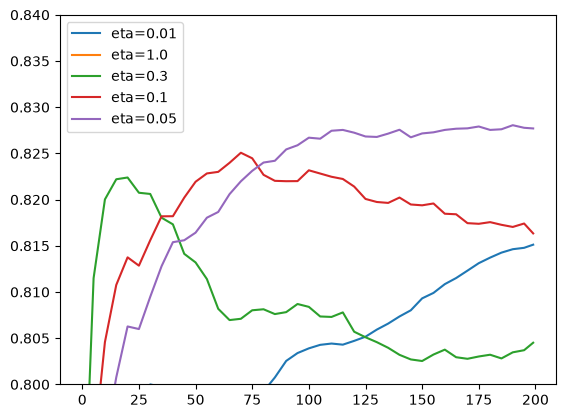

In [137]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

The learning rate controls how fast the model learns. With `eta=1.0` the
model takes the full correction from each new tree and quickly saturates -
its curve falls below the zoom window. With `eta=0.3` the validation AUC
rises fast, peaks early and then starts to degrade. With `eta=0.01` the
curve climbs slowly and would need many more rounds to reach its best. The
best trade-off is a middle value: `eta=0.1` reaches the top AUC and stays
stable, so we take it.

## Tuning max_depth
Next we fix `eta=0.1` and tune `max_depth` the same way. We reset `scores`
to start a fresh comparison, and train with `max_depth` of 6 - the baseline
we already have - then 3, 4 and 10:

In [142]:
from IPython.utils.capture import capture_output
scores = {}

for depth in [6, 3, 4, 10]:
    xgb_params = {
        'eta': 0.05,
        'max_depth': depth,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    with capture_output() as output:
        model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                          verbose_eval=5,
                          evals=watchlist)

    key = 'max_depth=%s' % depth
    scores[key] = parse_xgb_output(output)

scores.keys()

dict_keys(['max_depth=6', 'max_depth=3', 'max_depth=4', 'max_depth=10'])

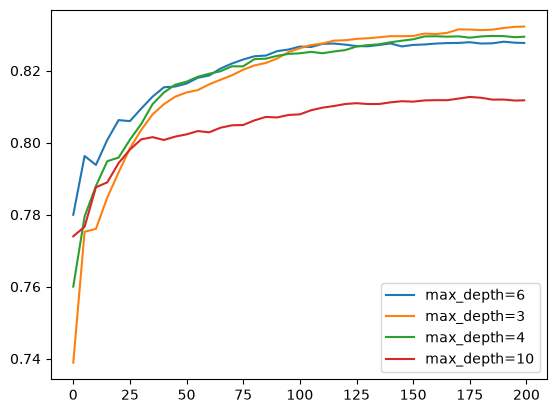

In [144]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

In [145]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)

In [147]:
key

'max_depth=10'

After plotting all four, the worst is clearly `max_depth=10`, so we remove
it from the comparison:

In [146]:
del scores['max_depth=10']

Then we plot the remaining curves again, zooming in with
`plt.ylim(0.8, 0.84)`: `max_depth=6` is the second worst, and the best depth
is a small one - `max_depth=3` gives the highest and most stable validation
AUC.

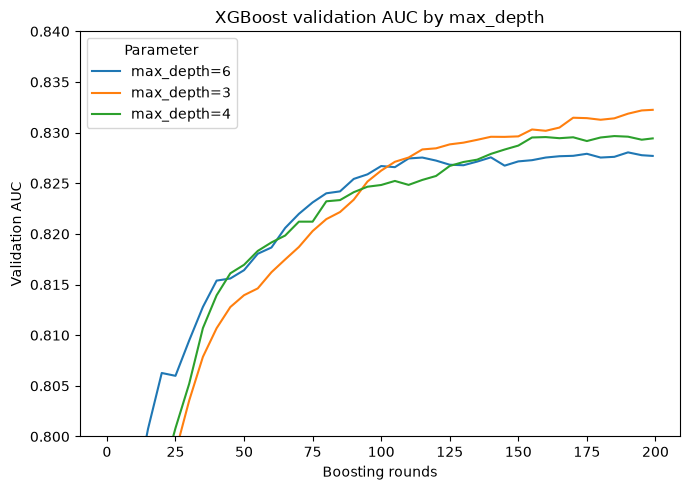

In [156]:
plt.figure(figsize=(7, 5), dpi=100)

for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key, )

plt.ylim(0.80, 0.84)
plt.title('XGBoost validation AUC by max_depth')
plt.xlabel('Boosting rounds')
plt.ylabel('Validation AUC')
plt.legend(title='Parameter', loc='upper left')

plt.tight_layout()
plt.show()

## Tuning min_child_weight

The last parameter is `min_child_weight`. We reset `scores` once more and
compare the baseline value of 1 with 10 and 30. For example, this is the run
with the value 30:


In [157]:
from IPython.utils.capture import capture_output
scores = {}

for min_w in [1,10,30]:
    xgb_params = {
        'eta': 0.05,
        'max_depth': 3,
        'min_child_weight': min_w,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }

    with capture_output() as output:
        model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                          verbose_eval=5,
                          evals=watchlist)

    key = 'min_child_weight=%s' % min_w
    scores[key] = parse_xgb_output(output)

scores.keys()

dict_keys(['min_child_weight=1', 'min_child_weight=10', 'min_child_weight=30'])

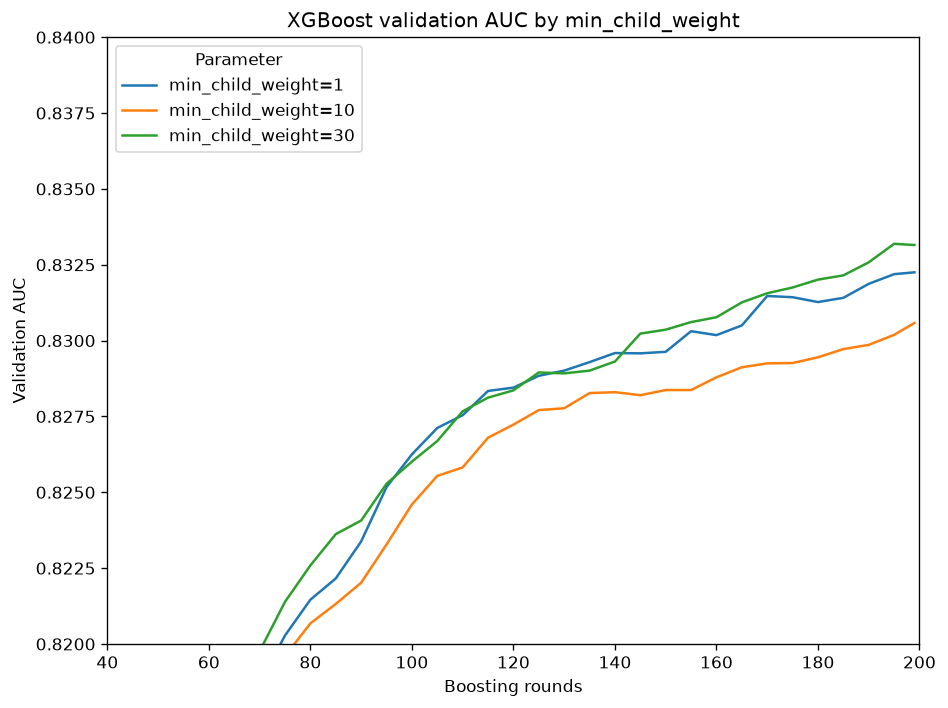

In [172]:
plt.figure(figsize=(8, 6), dpi=120)

for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key, )

plt.ylim(0.82, 0.84)
plt.xlim(40, 200)
plt.title('XGBoost validation AUC by min_child_weight')
plt.xlabel('Boosting rounds')
plt.ylabel('Validation AUC')
plt.legend(title='Parameter', loc='upper left')

plt.tight_layout()
plt.show()


## The final model

Putting it all together: `eta=0.1`, `max_depth=3`, `min_child_weight=1`.
Looking at the plots, the validation AUC is at its best around 175 boosting
rounds, so we train the final model of this unit with `num_boost_round=175`:

In [173]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

Other parameters worth knowing about:

- `subsample` - the fraction of the training data each tree sees.
- `colsample_bytree` - the fraction of features each tree sees, like the
  random feature subsets of random forest.
- `lambda` and `alpha` - the L2 and L1 regularization terms on the weights.

The full list is in the
[XGBoost parameter documentation](https://xgboost.readthedocs.io/en/latest/parameter.html).


## Notes !!!

<details><br>

XGBoost has various tunable parameters but the three most important ones are:

- `eta` (default=0.3)
  - It is also called `learning_rate` and is used to prevent overfitting by regularizing the weights of new features in each boosting step. range: [0, 1]
- `max_depth` (default=6)
  - Maximum depth of a tree. Increasing this value will make the model more complex and more likely to overfit. range: [0, inf]
- `min_child_weight` (default=1)
  - Minimum number of samples in leaf node. range: [0, inf]

For XGBoost models, there are other ways of finding the best parameters as well but the one we implement in the notebook follows the sequence of:

- First find the best value for `eta`
- Second, find the best value for `max_depth`
- Third, find the best value for `min_child_weight`

Other useful parameter are:

- `subsample` (default=1)
  - Subsample ratio of the training instances. Setting it to 0.5 means that model would randomly sample half of the training data prior to growing trees. range: (0, 1]
- `colsample_bytree` (default=1)
  - This is similar to random forest, where each tree is made with the subset of randomly choosen features.
- `lambda` (default=1)
  - Also called `reg_lambda`. L2 regularization term on weights. Increasing this value will make model more conservative.
- `alpha` (default=0)
  - Also called `reg_alpha`. L1 regularization term on weights. Increasing this value will make model more conservative.

### Alternative: Tuning XGBoost using a loop

Instead of repeating the training process manually for each `eta` value, you can use a loop to automate it (and other parameters to be tuned):
```python
# Train XGBoost models for each eta and store AUC results
scores = {} # dictionary to store results for each eta
etas = [0.01, 0.05, 0.1, 0.3, 1.0] # list of parameter values. in this case it is 'eta'.

for eta in etas:
    evals_result = {}

    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'binary:logistic',
        'eval_metric': 'auc',

        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }

    model = xgb.train(
        xgb_params,
        dtrain,
        evals=watchlist,
        verbose_eval=0,
        num_boost_round=200,
        evals_result=evals_result
    )

    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'eta={eta}'
    scores[key] = df_results
```

# 6.9 Selecting the best model

In this unit we compare the three model families we trained in this module -
decision tree, random forest and XGBoost - pick the winner, and train the
final model on the full training data to check it on the test set.


## Comparing the three models

Each family was tuned to its best parameters in the previous units, so we
train all three on the training data and compare their AUC on the same
validation set.

<p align="center">
  <img src="./images/09-final-model-01-comparing-validation-imagegen.jpg" alt="Comparing the three tuned models on the same validation set" width="640">
</p>

The tuned decision tree - `max_depth=6` and `min_samples_leaf=15` - gives:

In [174]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [175]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7854738320699426

The tuned random forest - 200 trees with `max_depth=10` and
`min_samples_leaf=3` - gives:

In [176]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=3,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [177]:
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8249709379767989

XGBoost wins with an AUC of about 0.836, ahead of random forest at about
0.825 and the single decision tree at about 0.785. This is a typical
outcome: boosted trees are very strong on tabular data. The price is that
XGBoost has many hyperparameters and can overfit quickly, so it needs more
attention during tuning than random forest, which works well almost out of
the box.


## Training the final model

Now that we have selected the best model and the best parameters, we use the
standard final-step recipe: combine the training and validation parts into
`df_full_train`, retrain with the same parameters, and evaluate once on the
test set - the data we have kept aside until now:

In [178]:
df_full_train = df_full_train.reset_index(drop=True)

y_full_train = (df_full_train.status == 'default').astype(int).values
del df_full_train['status']

We turn both `df_full_train` and the test set into feature matrices with a
newly fitted `DictVectorizer`, and wrap them in DMatrix objects - note that
the test DMatrix needs no labels:

In [179]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [ ]:
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                    feature_names=dv.get_feature_names_out().tolist())

dtest = xgb.DMatrix(X_test, feature_names=dv.get_feature_names_out().tolist())

Then we train the final model and look at its AUC on the test data:

In [185]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [186]:
y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

0.8290589414007137

The test AUC is about 0.832, close to the 0.836 we saw on validation. There
is no big gap between the two, which means the model generalized well: it
learned patterns that hold on data it has never seen.

## Notes

We select the final model from decision tree, random forest, or xgboost based on the best auc scores. After that we prepare the `df_full_train` and `df_test` to train and evaluate the final model. If there is not much difference between model auc scores on the train as well as test data then the model has generalized the patterns well enough.

Generally, XGBoost models perform better on tabular data than other machine learning models but the downside is that these model are easy to overfit cause of the high number of hyperparameter. Therefore, XGBoost models require a lot more attention for parameters tuning to optimize them.

# 6.9 Summary

In this final unit of the module we recap what we have learned about decision
trees and ensemble learning.

## What we learned in this module

The module started with a credit risk scoring project: we predict whether a
customer will default on a loan. On the way we learned four main things.

<p align="center">
  <img src="./images/10-summary-01-summary-slide-imagegen.jpg" alt="The four main points of the module: decision trees, best splits, random forest, and gradient boosting" width="640">
</p>

Decision trees learn if-then-else rules from data. The tree asks a sequence
of questions like "is the amount of assets greater than 3000" and assigns the
prediction in the leaves. To build the tree, the learning algorithm finds the
best split: the condition that gives the least impure left and right groups.
Left unchecked, this algorithm always grows a tree that memorizes the
training data, so we control it by limiting the maximum depth and the
minimal size of a group - `max_depth` and `min_samples_leaf` in
scikit-learn.

<p align="center">
  <img src="./images/10-summary-02-decision-tree-imagegen.jpg" alt="A decision tree asking questions about records, seniority, and job type" width="640">
</p>

<p align="center">
  <img src="./images/10-summary-03-overfitting-auc-imagegen.png" alt="An unrestricted tree scores 1.0 on train but only 0.654 on validation" width="640">
</p>

Random forest is a way of combining multiple decision trees: each tree sees
a random subset of features, all trees are trained independently and in
parallel, and their predictions are averaged. For an ensemble to work, its
models need to be diverse - the errors of one tree should be corrected by
the others. We tuned the number of trees, the depth and the leaf size, and
it improved the single tree considerably while needing little tuning
effort.

<p align="center">
  <img src="./images/10-summary-04-random-forest-imagegen.jpg" alt="Several diverse decision trees feed an averaged random forest prediction" width="640">
</p>

Gradient boosting trains models sequentially instead: each next model is
trained on the errors of the previous ones and tries to fix them. XGBoost is
the most popular implementation of this idea. It gave us the best model of
this module, but it also has the most knobs to tune - `eta`, `max_depth`,
`min_child_weight` and others - so it requires the most attention.

<p align="center">
  <img src="./images/10-summary-05-gradient-boosting-imagegen.jpg" alt="Gradient boosting trains models sequentially so each model corrects previous errors" width="640">
</p>

<p align="center">
  <img src="./images/10-summary-06-xgb-parameters-imagegen.jpg" alt="The XGBoost parameters eta, max_depth, and min_child_weight" width="640">
</p>

The final XGBoost model reached an AUC of about 0.836 on validation and
0.832 on test, compared to about 0.785 for the single decision tree. The
course continues in module 8, where we meet neural networks and train one
for image classification.

# 6.10 Explore more

<p align="center">
  <img src="./images/11-explore-more-01-ensemble-experiments-imagegen.jpg" alt="A dataset branches into EDA, feature importance, forests, and boosting before producing new insights." width="640">
</p>

*Figure: Explore several analyses and ensemble models to learn more from the same data.*

* For this dataset we didn't do EDA or feature engineering. You can do it to get more insights into the problem.
* For random forest, there are more parameters that we can tune. Check max_features and bootstrap.
* There's a variation of random forest caled "extremely randomized trees", or "extra trees". Instead of selecting the best split among all possible thresholds, it selects a few thresholds randomly and picks the best one among them. Because of that extra trees never overfit. In Scikit-Learn, they are implemented in ExtraTreesClassifier. Try it for this project.
* XGBoost can deal with NAs - we don't have to do fillna for it. Check if not filling NA's help improve performance.
* Experiment with other XGBoost parameters: subsample and colsample_bytree.
* When selecting the best split, decision trees find the most useful features. This information can be used for understanding which features are more important than otheres. See example here for random forest (it's the same for plain decision trees) and for xgboost
* Trees can also be used for solving the regression problems: check DecisionTreeRegressor, RandomForestRegressor and the objective=reg:squarederror parameter for XGBoost.  
